# Mood Transfer — demo walkthrough

Transfer the **mood** (colour, tone, lighting, atmosphere) of a reference photo onto a content photo.

* **Deep core:** pretrained VGG-19 + AdaIN decoder (Huang & Belongie 2017), Gatys et al. (2016) optimisation.
* **Mood layer (DIP):** Lab transfer modes, guided-filter photorealistic refinement, mood descriptors, post-processing.
* **Baselines:** Reinhard colour transfer, histogram (CDF) matching.

Runs on CPU, Apple MPS or CUDA. On **Colab**: *Runtime → Change runtime type → GPU*, then run the setup cell.

In [1]:
# --- Setup (Colab): clone/upload the repo first, e.g.
# !git clone <your-repo-url> mood-transfer
# %cd mood-transfer
# !pip install -q -r requirements.txt
# !python scripts/download_weights.py
import sys, os
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
print("repo root:", ROOT)

repo root: /Users/sarmadirfan/Desktop/DIP/mood-transfer


In [2]:
import numpy as np, matplotlib.pyplot as plt
from src.utils import get_device, default_size, load_image, list_images, set_seed
from src.mood import list_presets, describe_mood, palette_image, MoodConfig, adain_mood_transfer, apply_mode
from src.pipeline import transfer, TransferOptions, METHOD_LABELS
set_seed(0)
device = get_device(); SIZE = default_size(device)
print("device:", device, "| working size:", SIZE)
presets = list_presets(); print("mood presets:", list(presets))
contents = list_images(ROOT / "data" / "content"); print(len(contents), "content images")

def show(images, titles, h=3.2):
    fig, axes = plt.subplots(1, len(images), figsize=(h * len(images), h))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(np.clip(im, 0, 1)); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

device: mps | working size: 512
mood presets: ['Cold Blue Dusk', 'Dark Noir', 'Foggy / Misty', 'Golden Hour', 'Neon Night', 'Vintage Film']
10 content images


## 1. Mood descriptors of the presets
Dominant palette (k-means in Lab), brightness, contrast, saturation, colour temperature (McCamy CCT) and a rule-based label.

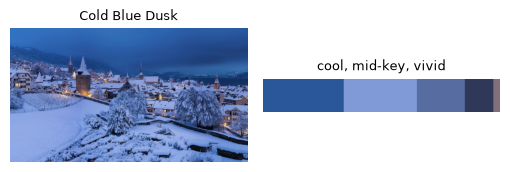

{'label': 'cool, mid-key, vivid', 'brightness': 0.459, 'contrast': 0.158, 'saturation': 0.54, 'colorfulness': 53.1, 'cct_K': 25000, 'warmth': -29.98, 'palette_hex': ['#2a569a', '#7f9ad8', '#586ca2', '#30395a', '#82707a'], 'palette_share': [0.342, 0.308, 0.202, 0.12, 0.028]}


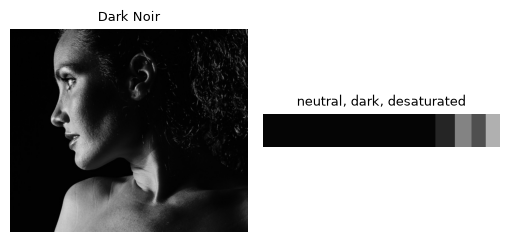

{'label': 'neutral, dark, desaturated', 'brightness': 0.126, 'contrast': 0.216, 'saturation': 0.0, 'colorfulness': 0.0, 'cct_K': 6504, 'warmth': 0.01, 'palette_hex': ['#060606', '#252525', '#838383', '#505050', '#b0b0b0'], 'palette_share': [0.728, 0.083, 0.069, 0.06, 0.06]}


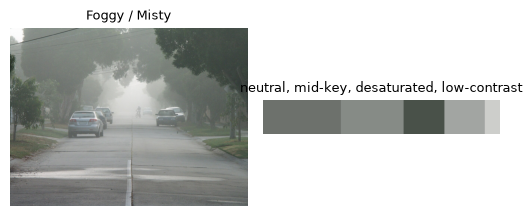

{'label': 'neutral, mid-key, desaturated, low-contrast', 'brightness': 0.534, 'contrast': 0.138, 'saturation': 0.057, 'colorfulness': 7.0, 'cct_K': 6445, 'warmth': 0.78, 'palette_hex': ['#6e726d', '#868b87', '#4a514a', '#a3a5a3', '#cececb'], 'palette_share': [0.329, 0.263, 0.172, 0.17, 0.066]}


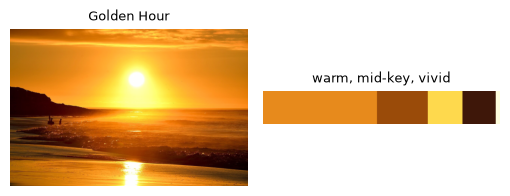

{'label': 'warm, mid-key, vivid', 'brightness': 0.572, 'contrast': 0.242, 'saturation': 0.858, 'colorfulness': 101.0, 'cct_K': 2661, 'warmth': 66.32, 'palette_hex': ['#e78a1c', '#9b4c0a', '#feda4d', '#3e1709', '#fffddd'], 'palette_share': [0.483, 0.214, 0.145, 0.139, 0.02]}


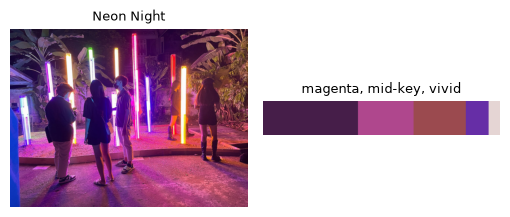

{'label': 'magenta, mid-key, vivid', 'brightness': 0.352, 'contrast': 0.198, 'saturation': 0.612, 'colorfulness': 80.9, 'cct_K': 4190, 'warmth': 3.33, 'palette_hex': ['#461f4a', '#af478d', '#9b4a50', '#662ea7', '#e5d5d4'], 'palette_share': [0.402, 0.233, 0.22, 0.097, 0.048]}


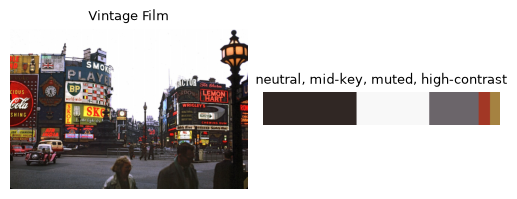

{'label': 'neutral, mid-key, muted, high-contrast', 'brightness': 0.498, 'contrast': 0.358, 'saturation': 0.203, 'colorfulness': 43.5, 'cct_K': 6080, 'warmth': 6.45, 'palette_hex': ['#302825', '#f9f8f9', '#6c666a', '#a23826', '#a58341'], 'palette_share': [0.396, 0.306, 0.208, 0.048, 0.042]}


In [3]:
for name, p in presets.items():
    im = load_image(p, 512); d = describe_mood(im)
    show([im, palette_image(d)], [name, d.label], h=2.6)
    print(d.as_dict())

## 2. All methods side by side

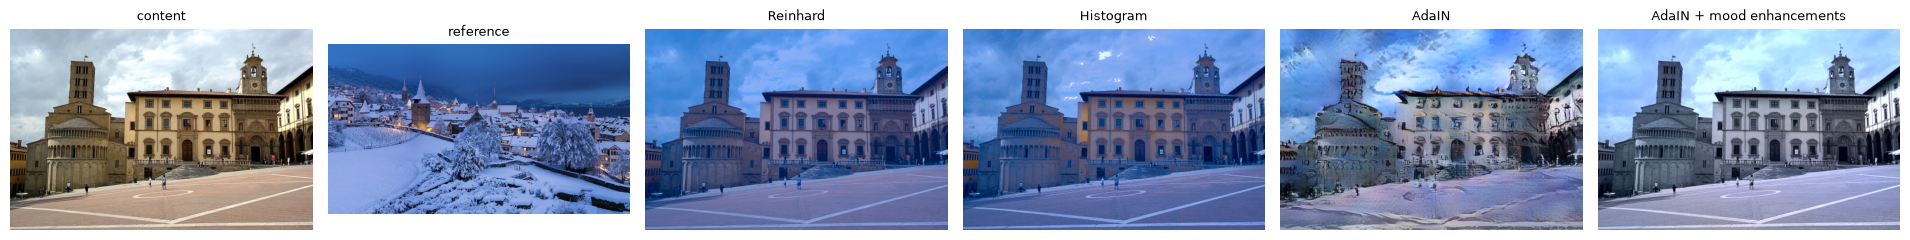

In [4]:
content = load_image(contents[0], 1024)
ref = load_image(list(presets.values())[0], 1024)
outs, titles = [content, ref], ["content", "reference"]
for m in ("reinhard", "hist", "adain", "adain_mood"):
    o, _ = transfer(content, ref, TransferOptions(method=m, size=SIZE), device)
    outs.append(o); titles.append(METHOD_LABELS[m])
show(outs, titles)

Gatys is slow (optimises pixels with L-BFGS). Reduce `gatys_iters` / `size` on CPU.

Gatys:   0%|          | 0/300 [00:00<?, ?it/s]

Gatys:   1%|          | 2/300 [00:00<00:14, 19.99it/s]

Gatys:   2%|▏         | 5/300 [00:00<00:13, 21.15it/s]

Gatys:   3%|▎         | 8/300 [00:00<00:13, 21.29it/s]

Gatys:   4%|▎         | 11/300 [00:00<00:13, 20.91it/s]

Gatys:   5%|▍         | 14/300 [00:00<00:13, 20.63it/s]

... (138 outputs left out)

Gatys:  98%|█████████▊| 294/300 [00:19<00:00, 15.12it/s]

Gatys:  99%|█████████▊| 296/300 [00:19<00:00, 15.16it/s]

Gatys:  99%|█████████▉| 298/300 [00:19<00:00, 15.19it/s]

Gatys: 100%|██████████| 300/300 [00:19<00:00, 15.13it/s]

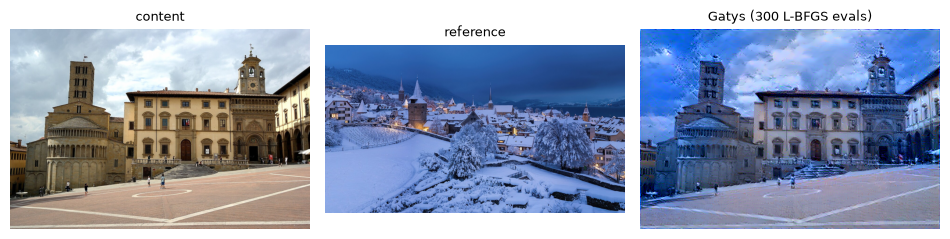

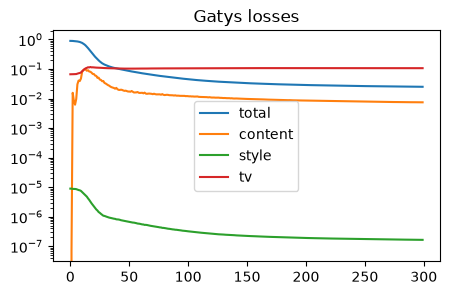

In [5]:
iters = 300 if device.type != "cpu" else 60
o, info = transfer(content, ref, TransferOptions(method="gatys", size=384 if device.type != "cpu" else 256, gatys_iters=iters), device)
show([content, ref, o], ["content", "reference", f"Gatys ({iters} L-BFGS evals)"])
plt.figure(figsize=(5, 3)); [plt.plot(v, label=k) for k, v in info["loss_history"].items()]
plt.yscale("log"); plt.legend(); plt.title("Gatys losses"); plt.show()

## 3. Strength α sweep

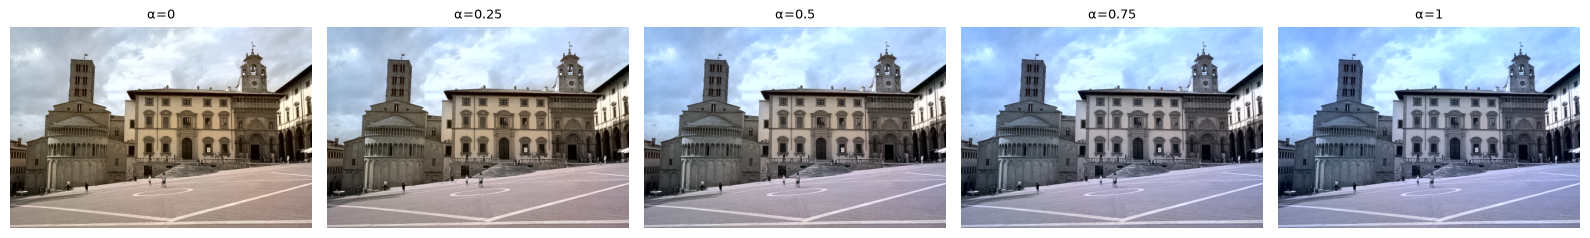

In [6]:
alphas = [0, 0.25, 0.5, 0.75, 1]
show([adain_mood_transfer(content, ref, MoodConfig(alpha=a, size=SIZE), device) for a in alphas],
     [f"α={a}" for a in alphas])

## 4. Transfer modes & photorealistic refinement

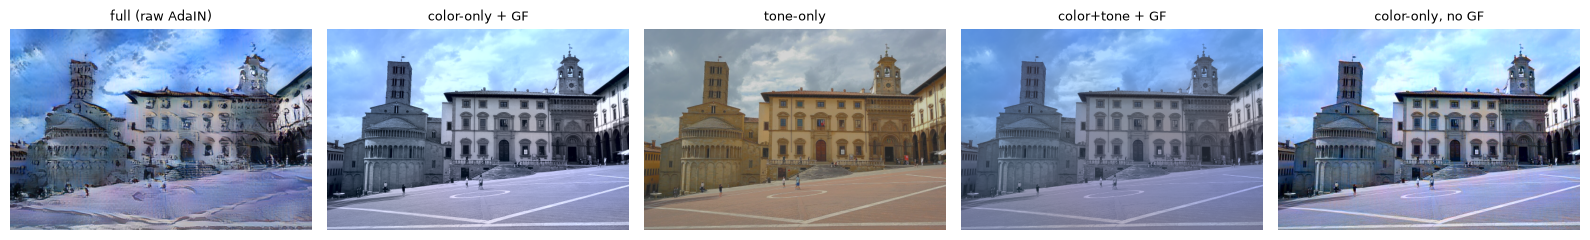

In [7]:
from src.adain import get_adain
from src.utils import resize_max_side
c = resize_max_side(content, SIZE)
st = get_adain(device).stylize(c, ref, alpha=1.0, size=SIZE)
show([st] + [apply_mode(c, st, m, refine=True) for m in ("color", "tone", "color_tone")] + [apply_mode(c, st, "color", refine=False)],
     ["full (raw AdaIN)", "color-only + GF", "tone-only", "color+tone + GF", "color-only, no GF"])

## 5. Multi-reference mood blending

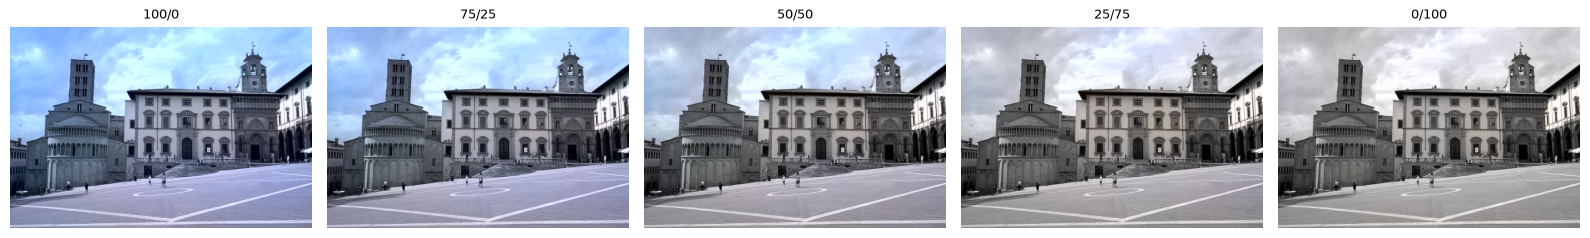

In [8]:
refs = [load_image(p, 1024) for p in list(presets.values())[:2]]
ws = [0, 0.25, 0.5, 0.75, 1]
show([adain_mood_transfer(content, refs, MoodConfig(size=SIZE, weights=[1 - w, w]), device) for w in ws],
     [f"{int(100*(1-w))}/{int(100*w)}" for w in ws])

## 6. Metrics for one result

In [9]:
from src.metrics import all_metrics, ClipScorer
clip = ClipScorer(str(device))
o, _ = transfer(content, ref, TransferOptions(method="adain_mood", size=SIZE), device)
c = resize_max_side(content, SIZE)
print({k: round(v, 4) for k, v in all_metrics(c, o, resize_max_side(ref, SIZE), clip, clip.image_similarity(c, ref)).items()})

/Users/sarmadirfan/Desktop/DIP/mood-transfer/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'ssim': 0.9984, 'lpips': 0.0012, 'lpips_rgb': 0.1592, 'lab_mean_dist': 22.9228, 'lab_std_dist': 9.7954, 'lab_stat_dist': 32.7182, 'wasserstein_lab': 13.1367, 'bhattacharyya': 0.7808, 'clip_sim': 0.396, 'clip_gain': 0.0137}


/Users/sarmadirfan/Desktop/DIP/mood-transfer/.venv/lib/python3.13/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/sarmadirfan/Desktop/DIP/mood-transfer/.venv/lib/python3.13/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


## 7. Full evaluation
The complete 10×6 evaluation, metrics CSV and all report figures are produced by:
```
python scripts/run_experiments.py --speed
```
Results: `results/metrics.csv`, `results/metrics_summary.md`, `results/figures/`.